# ch03_4. Iris 다중분류

## 실제 CSV 데이터로 붓꽃 품종 예측하기

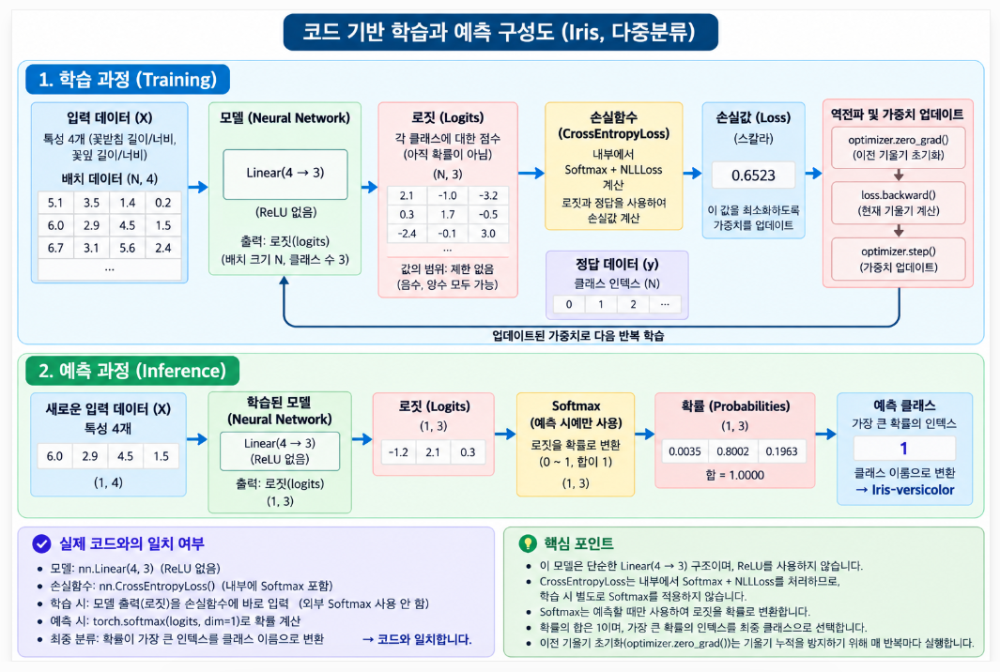

## 개요

- `iris.csv`를 불러와 데이터 구조를 확인합니다.
- 클래스별 확률을 해석하고 새로운 붓꽃 품종을 예측합니다.

## 1. 라이브러리와 CSV 파일 준비

사용 라이브러리:

- Pandas(판다스, 표 데이터 처리)
- scikit-learn(사이킷런, 훈련·테스트 분할)
- PyTorch(파이토치, 모델 학습)
- Matplotlib(맷플롯립, 결과 시각화)

`iris.csv`가 현재 폴더에 없으면 Colab에서 업로드 창이 열립니다.

In [17]:
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from torch import nn
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

torch.manual_seed(42)

data_path = Path("iris.csv")

if not data_path.exists():
    try:
        from google.colab import files
        files.upload()
    except ImportError:
        pass

if not data_path.exists():
    raise FileNotFoundError(
        "현재 폴더에 iris.csv를 넣은 뒤 다시 실행해 주세요."
    )

iris_data = pd.read_csv(data_path)

print("데이터 shape:", iris_data.shape)
print("열 이름:", iris_data.columns.tolist())

데이터 shape: (150, 5)
열 이름: ['F1', 'F2', 'F3', 'F4', 'label']


## 2. 데이터 구조 확인

Iris(아이리스, 붓꽃) 데이터는 150개이며, 세 품종이 각각 50개씩 들어 있습니다.

| 열 | 의미 | 단위 |
|---|---|---|
| `F1` | Sepal Length(시펄 렝스, 꽃받침 길이) | cm |
| `F2` | Sepal Width(시펄 위드, 꽃받침 너비) | cm |
| `F3` | Petal Length(페털 렝스, 꽃잎 길이) | cm |
| `F4` | Petal Width(페털 위드, 꽃잎 너비) | cm |
| `label` | Species(스피시즈, 붓꽃 품종) | 문자열 |

모델 학습 전에는 결측값과 클래스 분포를 먼저 확인합니다.

In [18]:
print("앞부분 5행:")
print(iris_data.head())

print()
print("결측값 수:", iris_data.isna().sum().sum())
print("중복 행 수:", iris_data.duplicated().sum())

print()
print("품종별 데이터 수:")
print(iris_data["label"].value_counts())

앞부분 5행:
    F1   F2   F3   F4        label
0  5.1  3.5  1.4  0.2  Iris-setosa
1  4.9  3.0  1.4  0.2  Iris-setosa
2  4.7  3.2  1.3  0.2  Iris-setosa
3  4.6  3.1  1.5  0.2  Iris-setosa
4  5.0  3.6  1.4  0.2  Iris-setosa

결측값 수: 0
중복 행 수: 3

품종별 데이터 수:
label
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64


## 3. 꽃잎 길이와 너비로 품종 분포 보기

실제 모델은 네 특성을 모두 사용합니다.

그래프에서는 품종 구분이 잘 드러나는 다음 두 특성만 표시합니다.

- `F3`: 꽃잎 길이
- `F4`: 꽃잎 너비

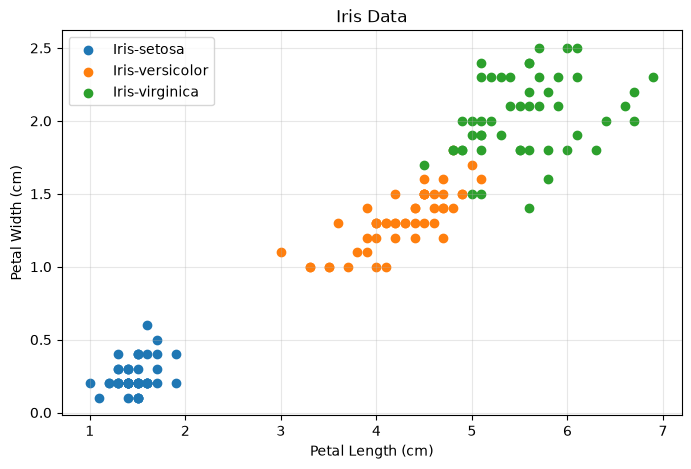

In [19]:
class_names = [
    "Iris-setosa",
    "Iris-versicolor",
    "Iris-virginica",
]

plt.figure(figsize=(8, 5))

for class_name in class_names:
    class_rows = iris_data[
        iris_data["label"] == class_name
    ]

    plt.scatter(
        class_rows["F3"],
        class_rows["F4"],
        label=class_name,
    )

plt.xlabel("Petal Length (cm)")
plt.ylabel("Petal Width (cm)")
plt.title("Iris Data")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

## 4. 입력과 정답 분리

입력 $X$는 네 개의 측정값이고, 정답 $y$는 붓꽃 품종입니다.

문자열 품종은 `CrossEntropyLoss()`에 바로 넣을 수 없으므로 클래스 번호로 변환합니다.

| 클래스 번호 | 품종 |
|---:|---|
| 0 | Iris-setosa |
| 1 | Iris-versicolor |
| 2 | Iris-virginica |

In [20]:
feature_columns = ["F1", "F2", "F3", "F4"]

label_to_index = {
    "Iris-setosa": 0,
    "Iris-versicolor": 1,
    "Iris-virginica": 2,
}

index_to_label = {
    index: label
    for label, index in label_to_index.items()
}

X = iris_data[
    feature_columns
].astype(np.float32)

y = iris_data["label"].map(
    label_to_index
).astype(np.int64)

print("입력 shape:", X.shape)
print("정답 shape:", y.shape)
print("정답 클래스:", sorted(y.unique()))

입력 shape: (150, 4)
정답 shape: (150,)
정답 클래스: [0, 1, 2]


## 5. 훈련 데이터와 테스트 데이터 분리

- 훈련 데이터: 120개
- 테스트 데이터: 30개
- `stratify=y`: 세 품종의 비율을 동일하게 유지
- `random_state=42`: 다시 실행해도 같은 분할 사용

각 품종은 훈련 데이터 40개, 테스트 데이터 10개로 나뉩니다.

In [21]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y,
)

print("훈련 데이터:", X_train.shape, y_train.shape)
print("테스트 데이터:", X_test.shape, y_test.shape)

print()
print("훈련 클래스별 개수:")
print(y_train.value_counts().sort_index())

print()
print("테스트 클래스별 개수:")
print(y_test.value_counts().sort_index())

훈련 데이터: (120, 4) (120,)
테스트 데이터: (30, 4) (30,)

훈련 클래스별 개수:
label
0    40
1    40
2    40
Name: count, dtype: int64

테스트 클래스별 개수:
label
0    10
1    10
2    10
Name: count, dtype: int64


## 6. 훈련 데이터 기준 표준화

네 특성의 평균과 표준편차는 훈련 데이터에서만 계산합니다.

$$
x_{\mathrm{scaled}}
=
\frac{x-\mu_{\mathrm{train}}}
{\sigma_{\mathrm{train}}}
$$

테스트 데이터에도 훈련 데이터의 평균과 표준편차를 그대로 사용합니다.

In [22]:
train_mean = X_train.mean()
train_std = X_train.std()

X_train_scaled = (
    X_train - train_mean
) / train_std

X_test_scaled = (
    X_test - train_mean
) / train_std

print("표준화 후 훈련 평균:")
print(X_train_scaled.mean().round(3))

print()
print("표준화 후 훈련 표준편차:")
print(X_train_scaled.std().round(3))

표준화 후 훈련 평균:
F1   -0.0
F2    0.0
F3    0.0
F4    0.0
dtype: float32

표준화 후 훈련 표준편차:
F1    1.0
F2    1.0
F3    1.0
F4    1.0
dtype: float32


## 7. Tensor로 변환

- 입력 Tensor 자료형: `torch.float32`
- 정답 Tensor 자료형: `torch.long`
- `CrossEntropyLoss()`의 정답 shape: `[데이터 수]`

In [23]:
X_train_tensor = torch.tensor(
    X_train_scaled.to_numpy(),
    dtype=torch.float32,
)

X_test_tensor = torch.tensor(
    X_test_scaled.to_numpy(),
    dtype=torch.float32,
)

y_train_tensor = torch.tensor(
    y_train.to_numpy(),
    dtype=torch.long,
)

y_test_tensor = torch.tensor(
    y_test.to_numpy(),
    dtype=torch.long,
)

print(
    "훈련 Tensor:",
    X_train_tensor.shape,
    y_train_tensor.shape,
)

print(
    "테스트 Tensor:",
    X_test_tensor.shape,
    y_test_tensor.shape,
)

훈련 Tensor: torch.Size([120, 4]) torch.Size([120])
테스트 Tensor: torch.Size([30, 4]) torch.Size([30])


## 8. 다중분류 모델

입력 특성 4개로 세 품종의 로짓 3개를 계산합니다.

```python
nn.Linear(4, 3)
```

모델 출력 shape:

$$
[\text{데이터 수},\ 3]
$$

같은 선형 계층이므로 별도의 모델 클래스를 만들지 않습니다.

In [24]:
torch.manual_seed(42)

model = nn.Linear(4, 3)

loss_function = nn.CrossEntropyLoss()

optimizer = torch.optim.SGD(
    model.parameters(),
    lr=0.1,
)

print(model)
print("가중치 shape:", model.weight.shape)
print("편향 shape:", model.bias.shape)

Linear(in_features=4, out_features=3, bias=True)
가중치 shape: torch.Size([3, 4])
편향 shape: torch.Size([3])


## 9. 모델 학습

학습 순서는 와 같습니다.

$$
\text{로짓 계산}
\rightarrow
\text{손실 계산}
\rightarrow
\text{역전파}
\rightarrow
\text{가중치 갱신}
$$

In [ ]:
epochs = 1500
loss_history = []

model.train()

for epoch in range(epochs):
    # 1. 클래스별 로짓(확률 변환 전 점수) 계산
    logits = model(
        X_train_tensor
    )
    print(logits)
    # 2. 교차엔트로피 손실 계산
    loss = loss_function(
        logits,
        y_train_tensor,
    )

    # 3. 이전 기울기 초기화 : 기울기 누적되므로
    optimizer.zero_grad()

    # 4. 역전파
    loss.backward()

    # 5. 가중치와 편향 갱신
    optimizer.step()

    loss_history.append(
        loss.item()
    )

print("처음 Loss:", loss_history[0])
print("마지막 Loss:", loss_history[-1])

tensor([[  7.1039,   2.3586, -11.2679],
        [ -2.9550,   1.4077,   1.8245],
        [ -4.4490,   3.8496,   2.2692],
        [  7.1242,   2.9078, -11.4529],
        [ -2.1513,   2.6665,  -0.1931],
        [ -6.1824,   2.9168,   4.9733],
        [ -1.9332,   2.5855,  -0.1701],
        [ -4.3925,   3.0750,   2.6865],
        [ -9.1242,   3.6705,   9.0059],
        [ -7.1451,   2.9687,   7.9106],
        [ -9.2157,   3.7265,   8.7558],
        [ -2.7731,   2.6505,   1.2453],
        [ -1.6147,   2.8911,  -1.8992],
        [ -1.3613,   3.1880,  -1.5114],
        [ -2.0223,   3.0656,  -0.5440],
        [  7.3565,   2.4364, -11.2350],
        [  8.6283,   2.2679, -11.6916],
        [ -7.6689,   3.4689,   6.1698],
        [ -4.8549,   2.5415,   4.2168],
        [  6.6539,   2.9173, -10.1351],
        [ -5.0806,   3.3785,   2.9623],
        [  8.7248,   2.3725, -11.9993],
        [ -6.5265,   3.4754,   6.7208],
        [  6.2714,   3.0083, -10.5342],
        [ -1.3276,   3.1276,  -1.8565],


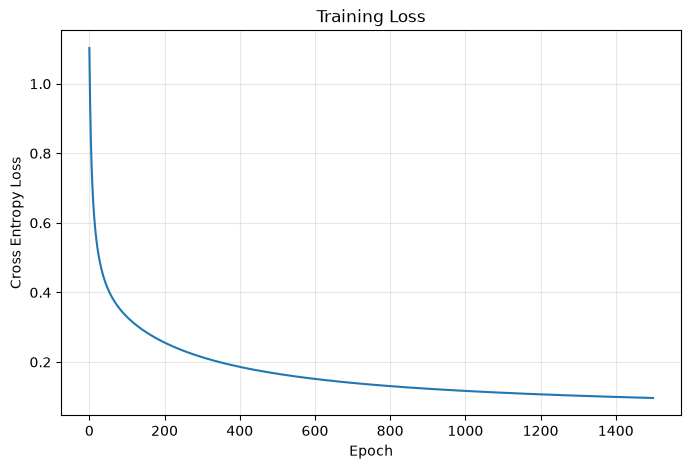

In [26]:
plt.figure(figsize=(8, 5))
plt.plot(loss_history)
plt.xlabel("Epoch")
plt.ylabel("Cross Entropy Loss")
plt.title("Training Loss")
plt.grid(alpha=0.3)
plt.show()

## 10. 훈련·테스트 정확도 확인

학습이 끝난 뒤 로짓에 `argmax(dim=1)`을 적용하여 예측 클래스를 구합니다.

Softmax는 클래스별 확률을 확인할 때만 사용합니다.

In [27]:
model.eval()

with torch.no_grad():
    train_logits = model(
        X_train_tensor
    )

    test_logits = model(
        X_test_tensor
    )

    train_predictions = torch.argmax(
        train_logits,
        dim=1,
    )

    test_predictions = torch.argmax(
        test_logits,
        dim=1,
    )

    test_probabilities = torch.softmax(
        test_logits,
        dim=1,
    )

    train_accuracy = (
        train_predictions == y_train_tensor
    ).float().mean()

    test_accuracy = (
        test_predictions == y_test_tensor
    ).float().mean()

print(f"훈련 정확도: {train_accuracy.item():.4f}")
print(f"테스트 정확도: {test_accuracy.item():.4f}")

훈련 정확도: 0.9750
테스트 정확도: 0.9667


## 11. 테스트 결과 일부 확인

각 데이터에 대해 다음 내용을 함께 확인합니다.

- 실제 품종
- 예측 품종
- 세 품종의 예측 확률

확률 합은 1입니다.

In [36]:
print(
    "번호  | 실제 품종            | "
    "예측 품종            | 확률 [setosa, versicolor, virginica]"
)

for index in range(10):
    actual = y_test_tensor[index].item()
    predicted = test_predictions[index].item()

    probabilities = [
        round(value, 4)
        for value in test_probabilities[index].tolist()
    ]

    print(
        f"{index:>4d} | "
        f"{index_to_label[actual]:<18} | "
        f"{index_to_label[predicted]:<18} | "
        f"{probabilities}"
    )

번호  | 실제 품종            | 예측 품종            | 확률 [setosa, versicolor, virginica]
   0 | Iris-setosa        | Iris-setosa        | [0.995, 0.005, 0.0]
   1 | Iris-virginica     | Iris-virginica     | [0.0006, 0.2972, 0.7022]
   2 | Iris-versicolor    | Iris-versicolor    | [0.0921, 0.9042, 0.0037]
   3 | Iris-versicolor    | Iris-versicolor    | [0.0483, 0.9475, 0.0042]
   4 | Iris-setosa        | Iris-setosa        | [0.9979, 0.0021, 0.0]
   5 | Iris-versicolor    | Iris-versicolor    | [0.0051, 0.7222, 0.2727]
   6 | Iris-setosa        | Iris-setosa        | [0.9995, 0.0005, 0.0]
   7 | Iris-setosa        | Iris-setosa        | [0.9763, 0.0237, 0.0]
   8 | Iris-virginica     | Iris-virginica     | [0.0, 0.0823, 0.9177]
   9 | Iris-versicolor    | Iris-versicolor    | [0.0266, 0.7747, 0.1986]


## 12. 테스트 혼동행렬

- 행: 실제 품종
- 열: 예측 품종
- 대각선: 올바르게 분류한 개수
- 대각선 밖: 다른 품종으로 잘못 분류한 개수

테스트 혼동행렬:
tensor([[10,  0,  0],
        [ 0,  9,  1],
        [ 0,  0, 10]])


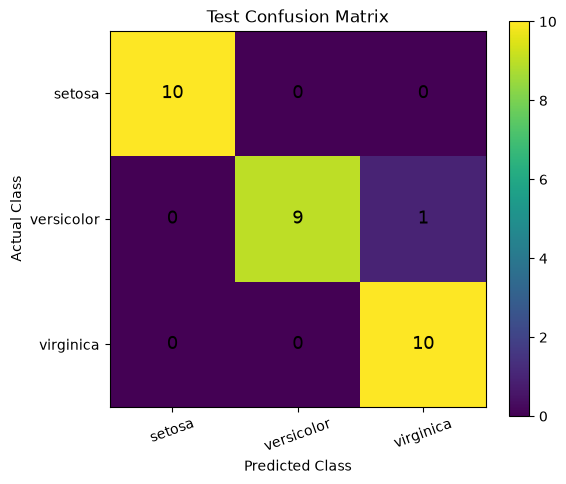

In [29]:
number_of_classes = 3

confusion_matrix = torch.zeros(
    number_of_classes,
    number_of_classes,
    dtype=torch.int64,
)

for actual, predicted in zip(
    y_test_tensor,
    test_predictions,
):
    confusion_matrix[
        actual,
        predicted,
    ] += 1

print("테스트 혼동행렬:")
print(confusion_matrix)

short_names = [
    "setosa",
    "versicolor",
    "virginica",
]

plt.figure(figsize=(6, 5))
plt.imshow(confusion_matrix.numpy())

plt.xticks(
    range(number_of_classes),
    short_names,
    rotation=20,
)

plt.yticks(
    range(number_of_classes),
    short_names,
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("Test Confusion Matrix")

for row in range(number_of_classes):
    for column in range(number_of_classes):
        plt.text(
            column,
            row,
            int(confusion_matrix[row, column]),
            ha="center",
            va="center",
            fontsize=13,
        )

plt.colorbar()
plt.tight_layout()
plt.show()

## 13. 품종별 정확도 확인

전체 정확도만 보면 어떤 품종을 어려워하는지 알기 어렵습니다.

따라서 품종별로 맞힌 비율을 따로 확인합니다.

In [30]:
for class_index, class_name in enumerate(
    class_names
):
    class_mask = (
        y_test_tensor == class_index
    )

    class_accuracy = (
        test_predictions[class_mask]
        == y_test_tensor[class_mask]
    ).float().mean()

    print(
        f"{class_name:<18}: "
        f"{class_accuracy.item():.4f}"
    )

Iris-setosa       : 1.0000
Iris-versicolor   : 0.9000
Iris-virginica    : 1.0000


## 14. 잘못 분류한 데이터 확인

틀린 데이터만 확인하면 어떤 품종끼리 혼동하는지 알 수 있습니다.

모두 맞혔다면 잘못 분류한 데이터가 없다고 출력됩니다.

In [31]:
wrong_indices = torch.where(
    test_predictions
    != y_test_tensor
)[0]

if len(wrong_indices) == 0:
    print("잘못 분류한 테스트 데이터가 없습니다.")
else:
    print("잘못 분류한 테스트 데이터:")

    for index in wrong_indices:
        index = index.item()

        actual = y_test_tensor[index].item()
        predicted = test_predictions[index].item()

        print(
            f"입력 {X_test.iloc[index].tolist()} | "
            f"실제 {index_to_label[actual]} | "
            f"예측 {index_to_label[predicted]}"
        )

잘못 분류한 테스트 데이터:
입력 [6.699999809265137, 3.0, 5.0, 1.7000000476837158] | 실제 Iris-versicolor | 예측 Iris-virginica


## 15. 새로운 붓꽃 품종 예측

새로운 붓꽃도 훈련 데이터의 평균과 표준편차로 표준화한 뒤 모델에 입력합니다.

입력 순서:

```text
[F1, F2, F3, F4]
```

In [42]:
new_flowers = pd.DataFrame(
    [
        [5.1, 3.5, 1.4, 0.2],
        [6.0, 2.9, 4.5, 1.5],
        [6.7, 3.1, 5.6, 2.4],
    ],
    columns=feature_columns,
    dtype=np.float32,
)

new_flowers_scaled = (
    new_flowers - train_mean
) / train_std

new_flowers_tensor = torch.tensor(
    new_flowers_scaled.to_numpy(),
    dtype=torch.float32,
)

model.eval()

with torch.no_grad():
    new_logits = model(
        new_flowers_tensor
    )

    new_probabilities = torch.softmax(
        new_logits,
        dim=1,
    )

    new_predictions = torch.argmax(
        new_logits,
        dim=1,
    )

for flower, probabilities, predicted in zip(
    new_flowers.to_numpy(),
    new_probabilities,
    new_predictions,
):
    probability_list = [
        round(value, 4)
        for value in probabilities.tolist()
    ]

    print(
        f"입력 {flower.tolist()} "
        f"→ {index_to_label[predicted.item()]} "
        f"| 확률 {probability_list} "
    )

입력 [5.099999904632568, 3.5, 1.399999976158142, 0.20000000298023224] → Iris-setosa | 확률 [0.9976, 0.0024, 0.0] 
입력 [6.0, 2.9000000953674316, 4.5, 1.5] → Iris-versicolor | 확률 [0.0012, 0.8693, 0.1295] 
입력 [6.699999809265137, 3.0999999046325684, 5.599999904632568, 2.4000000953674316] → Iris-virginica | 확률 [0.0, 0.0016, 0.9984] 


평가하면 아주 정상적인 다중분류 결과입니다. 특히 Iris-versicolor(아이리스 버시컬러)에서 확률이 분산되는 모습도 데이터 특성상 자연스럽습니다.

입력	예측 클래스	확률	평가
[5.1, 3.5, 1.4, 0.2]	Iris-setosa	[0.9953, 0.0047, 0.0]	✅ 매우 확실
[6.0, 2.9, 4.5, 1.5]	Iris-versicolor	[0.0035, 0.8002, 0.1963]	✅ 정상, 다만 virginica와 일부 경계
[6.7, 3.1, 5.6, 2.4]	Iris-virginica	[0.0, 0.0053, 0.9947]	✅ 매우 확실

## 17. 핵심 정리

- Iris 데이터는 150개이며 세 품종이 각각 50개입니다.
- 입력 4개, 클래스 3개이므로 `nn.Linear(4, 3)`을 사용합니다.
- 품종별 정확도와 오분류 데이터를 보면 모델의 약점을 더 쉽게 찾을 수 있습니다.